# imports

In [26]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;
import scipy.stats as st;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes
from sklearn.datasets import load_breast_cancer
from sklearn.datasets import fetch_openml

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error as MSE

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import SGDClassifier as SGDC;

from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay
from sklearn.model_selection import RandomizedSearchCV as RSCV;
from sklearn.model_selection import LeavePOut;
from sklearn.model_selection import GridSearchCV as GSCV;

from sklearn.feature_selection import RFE
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.feature_selection import f_regression
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectFromModel

from sklearn.neighbors import KNeighborsRegressor as KNNR
from sklearn.neighbors import KNeighborsClassifier as KNNC

from sklearn.gaussian_process import GaussianProcessClassifier as GPC
from sklearn.gaussian_process.kernels import RBF

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier as RFC;
from sklearn.ensemble import RandomForestRegressor as RFR;
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.ensemble import ExtraTreesClassifier as ETC;
from sklearn.ensemble import ExtraTreesRegressor as ETR;
from sklearn.ensemble import AdaBoostClassifier as AdaBoost;
from sklearn.ensemble import AdaBoostRegressor;
from sklearn.ensemble import GradientBoostingRegressor as GBR;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR
from sklearn.tree import plot_tree

from sklearn.naive_bayes import GaussianNB as GNB;

from sklearn.svm import SVC;
from sklearn.svm import SVR;

from sklearn.neural_network import MLPClassifier as MLPC
from sklearn.neural_network import MLPRegressor as MLPR;

from sklearn.utils.class_weight import compute_class_weight

from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.decomposition import PCA

from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import BorderlineSMOTE

from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import NearMiss
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours



from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA;

from yellowbrick.model_selection import LearningCurve

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

import warnings;warnings.simplefilter("ignore")

# 4. Доббавьте третий класс и примените LDA с n_components=2.

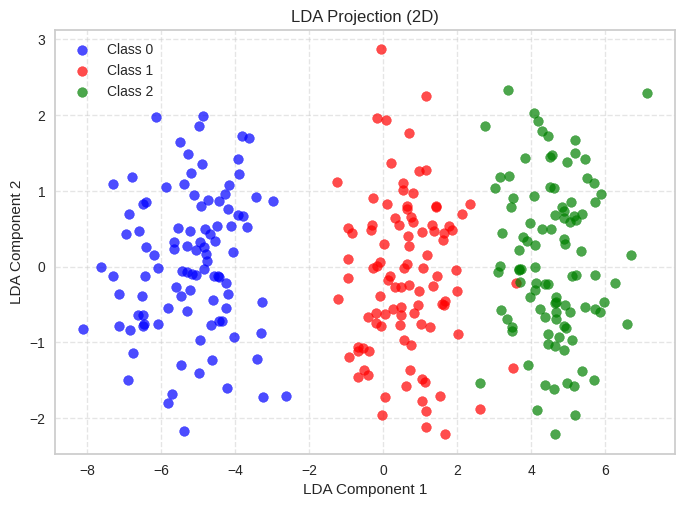

In [18]:
n_samples = 100

x1 = np.random.normal(2, 1, n_samples)
y1 = np.random.normal(2, 1, n_samples)
x2 = np.random.normal(6, 1, n_samples)
y2 = np.random.normal(6, 1, n_samples)
x3 = np.random.normal(9, 1, n_samples)
y3 = np.random.normal(9, 1, n_samples)

X = np.vstack((np.column_stack((x1, y1)), np.column_stack((x2, y2)),np.column_stack((x3, y3))))
y = np.hstack((np.zeros(n_samples), np.ones(n_samples), np.ones(n_samples)*2))
#print(y)
scaler = SC()
X_scaled = scaler.fit_transform(X)

lda = LDA(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)

# Визуализация в 2D
plt.scatter(X_lda[y == 0, 0], X_lda[y == 0, 1], c='blue', alpha=0.7, label='Class 0')
plt.scatter(X_lda[y == 1, 0], X_lda[y == 1, 1], c='red', alpha=0.7, label='Class 1')
plt.scatter(X_lda[y == 2, 0], X_lda[y == 2, 1], c='green', alpha=0.7, label='Class 2')

plt.title('LDA Projection (2D)')
plt.xlabel('LDA Component 1')
plt.ylabel('LDA Component 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


# 5. Сравните LDA с PCA на этих же данных. Какой метод лучше разделяет классы?

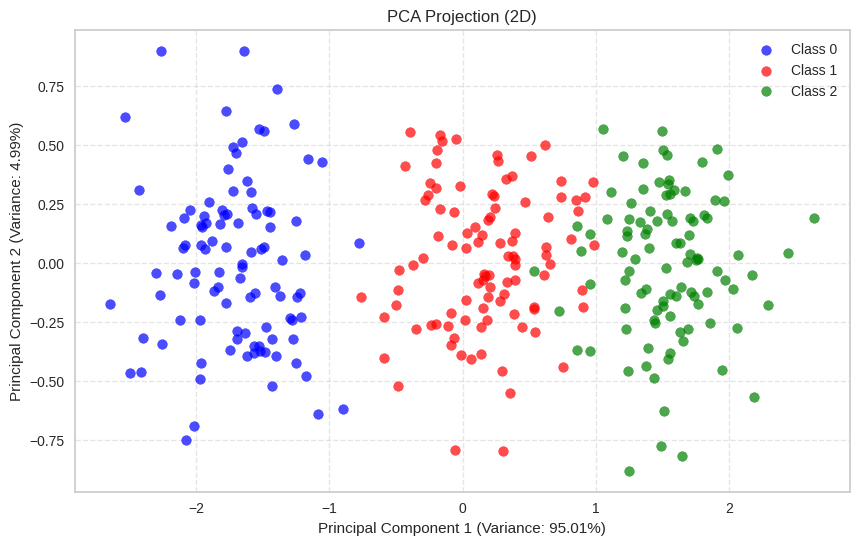

Объясненная дисперсия компонентов PCA:
[0.95008644 0.04991356]
Суммарная объясненная дисперсия: 1.0


In [31]:
n_samples = 100

x1 = np.random.normal(2, 1, n_samples)
y1 = np.random.normal(2, 1, n_samples)
x2 = np.random.normal(6, 1, n_samples)
y2 = np.random.normal(6, 1, n_samples)
x3 = np.random.normal(9, 1, n_samples)
y3 = np.random.normal(9, 1, n_samples)

X = np.vstack((np.column_stack((x1, y1)), np.column_stack((x2, y2)),np.column_stack((x3, y3))))
y = np.hstack((np.zeros(n_samples), np.ones(n_samples), np.ones(n_samples)*2))

#print(y)
scaler = SC()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
plt.scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], c='blue', alpha=0.7, label='Class 0')
plt.scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], c='red', alpha=0.7, label='Class 1')
plt.scatter(X_pca[y == 2, 0], X_pca[y == 2, 1], c='green', alpha=0.7, label='Class 2')

plt.title('PCA Projection (2D)')
plt.xlabel('Principal Component 1 (Variance: {:.2f}%)'.format(pca.explained_variance_ratio_[0]*100))
plt.ylabel('Principal Component 2 (Variance: {:.2f}%)'.format(pca.explained_variance_ratio_[1]*100))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("Объясненная дисперсия компонентов PCA:")
print(pca.explained_variance_ratio_)
print("Суммарная объясненная дисперсия:", sum(pca.explained_variance_ratio_))

PCA разделимость (точность KNN): 0.960
LDA разделимость (точность KNN): 0.990


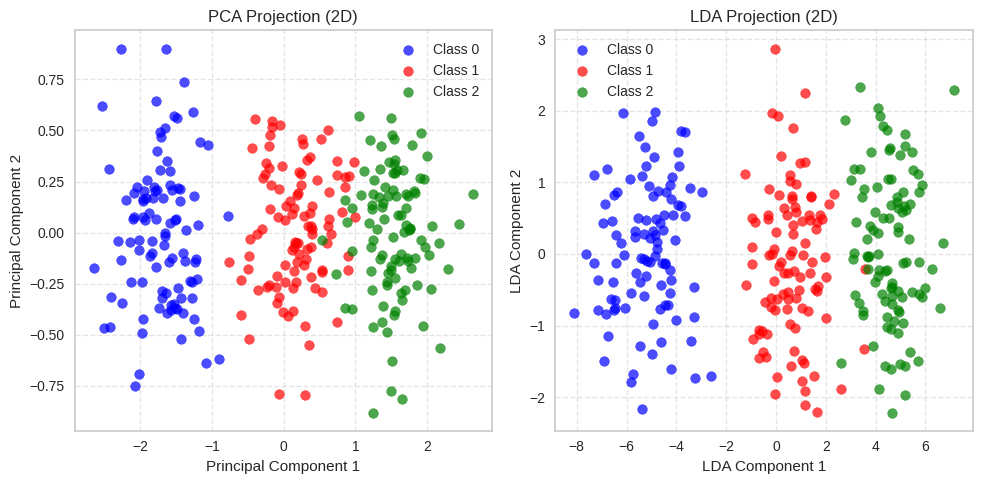

In [32]:
# Функция для оценки разделимости классов
def evaluate_separation(X_transformed, y):
    # Простая оценка через точность KNN
    knn = KNNC(n_neighbors=3)
    scores = cross_val_score(knn, X_transformed, y, cv=5)
    return np.mean(scores)

# Оценка разделимости
pca_score = evaluate_separation(X_pca, y)
lda_score = evaluate_separation(X_lda, y)

print(f"PCA разделимость (точность KNN): {pca_score:.3f}")
print(f"LDA разделимость (точность KNN): {lda_score:.3f}")

plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], c='blue', alpha=0.7, label='Class 0')
plt.scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], c='red', alpha=0.7, label='Class 1')
plt.scatter(X_pca[y == 2, 0], X_pca[y == 2, 1], c='green', alpha=0.7, label='Class 2')
plt.title('PCA Projection (2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.scatter(X_lda[y == 0, 0], X_lda[y == 0, 1], c='blue', alpha=0.7, label='Class 0')
plt.scatter(X_lda[y == 1, 0], X_lda[y == 1, 1], c='red', alpha=0.7, label='Class 1')
plt.scatter(X_lda[y == 2, 0], X_lda[y == 2, 1], c='green', alpha=0.7, label='Class 2')
plt.title('LDA Projection (2D)')
plt.xlabel('LDA Component 1')
plt.ylabel('LDA Component 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Визуально PCA и LDA очень схожи, поэтому обучим KNN классификатор и проверим score на кросс-валидации - рузультат работы метода K ближайших соседей напрямую зависит от качества разделения классов, поэтому, сравнивая по качеству классификации KNN можно определить качество разделения данных с помощью PCA и LDA

Как видно из cross_validation, PCA хуже разделяет данные, чем LDA:
\
cross_val_score для PCA = 0.96 < cross_val_score для LDA = 0.99
